### Instructions

- Answer the questions in this notebook, ask me question if you don't understand something
- Once your work is finished: restart the kernel, run all cells in order and check that the outputs are correct.
- Upload the notebook on moodle, `SL_TP1_NAME1_NAME2_NAME3`. Repeat the submission for each member.
- Put your names on the cell below.

**Deadline: Friday, December 18, 11:59 CET**.

Your Names : FERNANDES--STRAG Henry, TORRES--LEGUET Alexandre
</div>

## Store Management MDP

You own a bike store. During week $t$, the (random) demand is $D_t$ units. 
On Monday morning you may choose to command $A_t$ additional units: they are delivered immediately before the shop opens. For each week:

  * Maintenance cost: $h$ per unit in stock left from the previous week (no maintenance is needed for newly commanded items)
  * Command cost: $c$ for each unit ordered + $c_0$ per command
  * Sales profit: $p$ per unit sold
  * Constraint: 
    - your warehouse has a maximal capacity of $M$ unit (any additionnal bike gets stolen)
    - you cannot sell bikes that you don't have in stock


* State: number of bikes in stock left from the last week => state space $\mathcal{S} = \{0,\dots, M\}$
* Action: number of bikes commanded at the beginning of the week => action space $\mathcal{A} = \{0, \dots ,M\}$ 
* Reward = balance of the week: if you command $a_t$ bikes,
$$r_t = -c_0 \mathbb{1}_{(a_t >0)}- c \times a_t - h\times s_t + p \times \min(D_t, s_t+a_t, M)$$
* Transitions: you end the week with the number of bikes $$s_{t+1} = \max\big(0, \min(M, s_t + a_t)  - D_t \big)$$ 

Our two goal is to maximize:
 
 - The discounted sum of rewards, starting from an initial stock $s_1$, that is to find a policy whose value is 
$$V^\star(s_1) = \max_{\pi}\mathbb{E}_{\pi}\left[\sum_{t=1}^{\infty} \gamma^{s-1}r_t  | S_1 = s_1\right].$$
 - The sum of reward for an horizon $H = 52$, one year. 
$$V^\star_1(s_1) = \max_{\pi}\mathbb{E}_{\pi}\left[\sum_{t=1}^{H} r_t | S_1 = s_1\right].$$

In [2]:
import numpy as np
import random as rd
import gymnasium as gym
from matplotlib import pyplot as plt
import time

# plt.rcParams.update({
#     "font.size": 14,
#     "axes.titlesize": 18,
#     "axes.labelsize": 16,
#     "xtick.labelsize": 14,
#     "ytick.labelsize": 14,
#     "legend.fontsize": 14,
# })

### Problem parameters 

In [3]:
M = 15  # stock capacity
h = 0.3  # maintenance cost (per unit)
c = 0.5  # ordering cost (per unit)
c0 = 0.3  # fix delivery cost per command
p = 1  # selling price (per unit)

### Specifying the demand distribution 

As an example of demand distribution, we choose a (truncated) geometric distribution, for which 
$$\mathbb{P}(D_t = m) = q(1-q)^m \ \ \forall m \in \{0,\dots,M-1\}$$
and $\mathbb{P}(D_t = M) = 1 - \sum_{m=0}^{M-1}\mathbb{P}(D_t = m)$. We provide below a function that simulate the demand. 

In [10]:
# demand distribution (truncated geometric with parameter q)
q = 0.1
pdem = np.array([q * (1 - q) ** m for m in range(M + 1)])
pdem[M] = pdem[M] + 1 - np.sum(pdem)

print("the average demand is ", np.sum([m * pdem[m] for m in range(M + 1)]))


def SimuDemand(pdem):
    cpdem = np.cumsum(pdem)
    i = 0
    u = rd.random()
    while u > cpdem[i]:
        i = i + 1
    return i


print("a simulated demand is ", SimuDemand(pdem))

the average demand is  7.1469798111481575
a simulated demand is  10


### Encoding the MDP as a gymnasium environment

This is just a  toy example on how to create a gymnasium environment. 

Note that our environment is an example of tabular MDP for which the transition probabilities $P(s'|s,a)$ and the mean rewards $r(s,a)$ can actually be computed in closed form. Therefore, we provide the transitions $(P)$ and mean rewards $(r)$ as attributes of the class. 

In [13]:
def nextstate(s, a, d, M):
    # computes the next state if the demand is d
    return max(0, min(M, s + a) - d)


def nextreward(s, a, d, M, c, c0, h, p):
    # computes the reward if the demand is d
    rew = -c * a - h * s + p * min(M, d, s + a)
    if a > 0:
        rew = rew - c0
    return rew


# To compare policy on the same demand
gamma = 0.97  # discount factor
T = int(np.log(1 / (0.001 * (1 - gamma))) / np.log(1 / gamma))
Demand_list = [SimuDemand(pdem) for i in range(T)]


class StoreManagement(gym.Env):
    """
    Retail Store Management environment
    The environment defines which actions can be taken at which point and
    when the agent receives which reward.
    """

    def __init__(self, FirstState, M=15, h=0.3, c=0.5, c0=0.3, p=1, q=0.1):

        # General variables defining the environment
        self.Stock_Capacity = M
        self.Maintenance_Cost = h
        self.Order_Cost = c
        self.Delivery_Cost = c0
        self.Selling_Price = p
        pdem = np.array([q * (1 - q) ** m for m in range(M + 1)])
        pdem[M] = pdem[M] + 1 - np.sum(pdem)
        self.Demand_Distribution = pdem

        # For comparison of policy
        self.Demand_list = Demand_list

        # Define the action space
        self.action_space = gym.spaces.Discrete(self.Stock_Capacity + 1)

        # Define the state space (state space = observation space in this example)
        self.observation_space = gym.spaces.Discrete(self.Stock_Capacity + 1)

        # current time step
        self.curr_step = -1  #

        # initial state
        self.state = FirstState

        # computation of the MDP parameters
        P = np.zeros((M + 1, M + 1, M + 1))  # P[s,a,s'] = p(s' | s,a)
        r = np.zeros(
            (M + 1, M + 1)
        )  # r[s,a] = average reward received in state s when playing action a
        ## iteration over all possible states, actions, and possible demand values
        for a in range(M + 1):
            for s in range(M + 1):
                for d in range(M + 1):
                    # next state and reward with demand d
                    ns = max(0, min(M, s + a) - d)
                    reward = -c * a - h * s + p * min(M, d, s + a)
                    if a > 0:
                        reward = reward - c0
                    P[s, a, ns] += pdem[d]
                    r[s, a] += pdem[d] * reward
        self.P = P  # P[s,a,ns] = P(ns | s,a)
        self.r = r  # r[s,a] = r(s,a)

    def step(self, action, repro=False):
        """
        simulates a transition following an action in the current state
        action : int
        """
        self.curr_step += 1
        # simulate the demand
        Demand = SimuDemand(self.Demand_Distribution)

        # simulate for a fixed demand list
        if repro:
            Demand = self.Demand_list[self.curr_step]

        # compute the reward
        reward = nextreward(
            self.state,
            action,
            Demand,
            self.Stock_Capacity,
            self.Order_Cost,
            self.Delivery_Cost,
            self.Maintenance_Cost,
            self.Selling_Price,
        )
        # compute the next state
        self.state = nextstate(self.state, action, Demand, self.Stock_Capacity)
        # return 4 elements: observation / reward / termination? / truncation ? / information
        return self.state, reward, False, False, {}

    def reset(self, InitialStock):
        """
        Reset the state of the environment and returns an initial observation.
        """
        self.curr_step = -1
        self.state = InitialStock

    def _render(self, mode="human"):
        """optional visualization of the interaction: none here"""
        return

### A function that simulates a trajectory under a policy Pi starting from some state $s_0$

**Complete the function below to simulate a trajectory of length $T$ from an initial state $s_0$ under a policy Pi**

Write a function `SimulateTrajectory` that takes 3 arguments T, Pi and s0. It should initialize a StoreManagement environment in the state s0. Then, for T steps, will will:
- query the state of the environment
- choose an action according to the policy
- get a new state and a reward by calling `state, reward, _, _, _ = env.step(action)` (where `env` is the environment)

The function should return two arrays of length `T`: one for the states visited and one for the rewards obtained.

In [14]:
def SimulateTrajectory(T, Pi, s0, repro=False):
    """return a vector of T successive states and a vector of T successive rewards"""
    Rewards = np.zeros(T)
    States = np.zeros(T + 1)
    env = StoreManagement(s0)
    state = s0
    States[0] = s0
    for t in range(T):
        action = Pi(state)
        state, reward, _, _, _ = env.step(action, repro)
        Rewards[t], States[t + 1] = reward, state
    return States, Rewards

### Running simulations with three simple baselines 

In [15]:
s0 = 10  # initial stock
gamma = 0.97  # discount factor


def PiUniform(s):
    # pick uniformly at random in {0,1,...,M-s}
    x = rd.sample(range(M + 1 - s), 1)
    return x[0]


def PiConstant(s, c=3):
    # oder a constant number of c bikes
    return min(c, M - s)


def PiThreshold(s, m1=4, m2=10):
    # if less than m1 bikes in stock, refill it up to m2
    action = 0
    if s <= m1:
        action = m2 - s
    return action

In [16]:
# Policy factories: return a policy s -> action with the hyperparameters fixed,
# so that it can be passed to SimulateTrajectory / EvaluatePolicy* (which call Pi(s)).


def MakeUniformPolicy():
    return lambda s: PiUniform(s)


def MakeConstantPolicy(c=3):
    return lambda s: PiConstant(s, c=c)


def MakeThresholdPolicy(m1=4, m2=10):
    return lambda s: PiThreshold(s, m1=m1, m2=m2)

**Plot the cumulative discounted return as a function of time for the hundred first time steps and for the three baselines.**

The cumulative discounted return at time $t$ is defined by :

$$G_t = \sum_{s = t}^\infty \gamma^{s-t} r_s $$

**Plot the cumulative reward as a function of the time for the three baselines.**

For each quantity, you should plot one trajectory for each policy, all on the same graph. Don't forget to add legends to the graph.

In [62]:
T = int(
    np.log(1 / (0.001 * (1 - gamma))) / np.log(1 / gamma)
)  # truncation of the infinite sum

StatesU, RewardsU = SimulateTrajectory(T, PiUniform, s0, repro=True)
StatesC, RewardsC = SimulateTrajectory(T, PiConstant, s0, repro=True)
StatesT, RewardsT = SimulateTrajectory(T, PiThreshold, s0, repro=True)

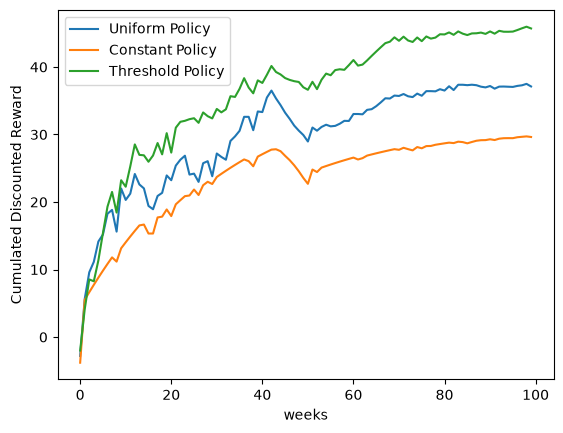

In [68]:
def cummulativeDiscountedRewards(Rewards, gamma):
    cum = 0
    CDR = []
    for i in range(len(Rewards)):
        cum += Rewards[i] * (gamma**i)
        # Rewards[0] = r_1, discounted by gamma^0 = 1, Rewards[1] = r_2 discounted by gamma^1...
        # Rewards[i] = r_{i+1} discounted by gamma^i
        CDR.append(cum)
    return CDR

CDRU = cummulativeDiscountedRewards(RewardsU, gamma)
CDRC = cummulativeDiscountedRewards(RewardsC, gamma)
CDRT = cummulativeDiscountedRewards(RewardsT, gamma)

plt.figure(1)
plt.plot(range(100), CDRU[:100], label="Uniform Policy")
plt.plot(range(100), CDRC[:100], label="Constant Policy")
plt.plot(range(100), CDRT[:100], label="Threshold Policy")
plt.xlabel("weeks")
plt.ylabel("Cumulated Discounted Reward")
plt.legend()

**Comment on the plots**

What is the discounted return, why does it look like that ? Which strategy looks the best ?

<div style="border-left: 4px solid #2a7ae2; background-color: rgba(42, 122, 226, 0.10); padding: 6px 14px; border-radius: 4px;">

The return is the sum of all the future rewards up to a given horizon (which may be infinite). It's also called the cumulative rewards. The discounted return is a way to define this return for infinite horizons, by down-weighting each future timestep by a factor $\gamma < 1$. Provided that the rewards are bounded, this makes the discounted return :

$$G_t = \sum_{t=1}^{+\infty} \gamma^{t-1} R_t$$

well defined.

Because the down-weighting is exponential ($\gamma \gamma \gamma ...$), up to some point, future rewards will contribute to approximately 0 to this return, this is why for all the 3 policies this return flattens in the future. This is also why we are able to compute this infinite horizon here, without having to add an infinite amount of rewards (we compute the horizon T after which rewards are not considered to contribute, because their associated down-weighting $T^\gamma$ is below what float values can represent).

The strategy that always picks the same action (3 bikes ordered) looks the worse, while the threshold strategy looks the best.

</div>

**Evolution of the stock**

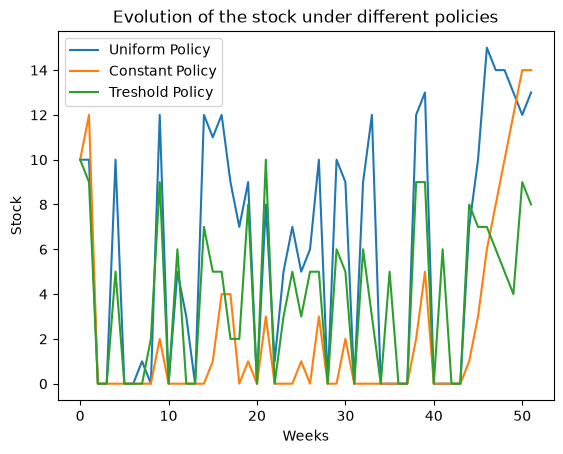

In [29]:
plt.figure(4)
plt.plot(StatesU[:52], label="Uniform Policy")
plt.xlabel("Weeks")
plt.ylabel("Stock")
plt.title("Evolution of the stock under different policies")

# plt.figure()
plt.plot(StatesC[:52], label="Constant Policy")
# plt.xlabel("weeks")
# plt.ylabel("stock")
# plt.title("Evolution of the stock under a constant")
# plt.figure()

plt.plot(StatesT[:52], label="Treshold Policy")
# plt.xlabel("weeks")
# plt.ylabel("stock")
# plt.title("Evolution of the stock under a threshold policy")
plt.legend()
plt.savefig("evolution_stock_diff.pdf", format="pdf")

**Bonus** How would you compare the evolution of the stock over 52 weeks on one run if you were to run each policy. 

<div style="border-left: 4px solid #2a7ae2; background-color: rgba(42, 122, 226, 0.10); padding: 6px 14px; border-radius: 4px;">

**Your answer:**

<!-- Write your answer below this line, and keep the </div> at the end. -->



</div>

# Dynamic Programming

So far, when doing simulations, we just interacted with the environements with calls to the "step" functions (which boils down to simulating the demand each week). However, we assume that all the parameters (including the demand distribution itself, paramterized by $q$) are known, we can evaluate policies, and compute the optimal policy using the knowledge of the MDP parameters (encoded in env.P and env.r).

In [30]:
env = StoreManagement(0, M=15, h=0.3, c=0.5, c0=0.3, p=1, q=0.1)

# MDP parameters
P = env.P  # P[s,a,s'] = p(s' | s,a)
r = env.r  # r[s,a] = average reward received in state s when playing action a

## Evaluation of deterministic policies


In this section we propose to ways to evaluate fixed policies for the discounted reward value function $V^\pi(s)$ and the cumulative reward function $V_1^\pi(s)$ for $H = 52$ 

For Monte Carlo methods, observe that we do *not* need the knowledge of $P$ and $r$ for this method, simulating trajectories is enough.

However, for the Bellman operator methods one need to have access to $P$ and $r$.

### Approximate method

#### Monte Carlo

**Write a Monte Carlo algorithm to estimate the discounted value function $V^\pi(s)$** 


We collect `MC` values for the sum of discounted rewards over long enough trajectories starting at $s$, then compute the mean of these `MC` values.

We need to compute trajectories from *all* states.

In [55]:
## Computes the values in each state by Monte-Carlo simulation (needs many simulations to be precise)

# on reprend une fonction similaire à ummulativeDiscountedRewards (mais qui donne seulement la somme finale)
# avec numpy : np.sum([Rewards[t] * (gamma**t) for t in range(T)])
def DiscountedRewards(Rewards, gamma):
    DR = 0
    for i in range(len(Rewards)):
        DR += Rewards[i] * (gamma**i)
    return DR

MC = 100  # number of Monte-Carlo simulations

# uniform policy
Policy = MakeUniformPolicy()
DTValuesMC_U = np.zeros(M + 1)
for i in range(M + 1):
    s1 = i
    val = 0
    for j in range(MC):
        States, Rewards = SimulateTrajectory(T, Policy, s1, repro=True)
        val += DiscountedRewards(Rewards, gamma)
    DTValuesMC_U[i] = val / MC

# constant policy
Policy = MakeConstantPolicy(c=3)
DTValuesMC_C = np.zeros(M + 1)
for i in range(M + 1):
    s1 = i
    val = 0
    for j in range(MC):
        States, Rewards = SimulateTrajectory(T, Policy, s1, repro=True)
        val += DiscountedRewards(Rewards, gamma)
    DTValuesMC_C[i] = val / MC

# threshold policy
Policy = MakeThresholdPolicy()
DTValuesMC_T = np.zeros(M + 1)
for i in range(M + 1):
    s1 = i
    val = 0
    for j in range(MC):
        States, Rewards = SimulateTrajectory(T, Policy, s1, repro=True)
        val += DiscountedRewards(Rewards, gamma)
    DTValuesMC_T[i] = val / MC

The estimated Discounted Value Function in each states for the threshold policy are:
[45.85799225 46.05799225 46.25799225 46.45799225 46.65799225 48.88199225
 46.64199225 47.02099225 47.39999225 47.77899225 48.15799225 48.53699225
 48.91599225 49.29499225 49.67399225 50.05299225]


Text(0, 0.5, 'Values')

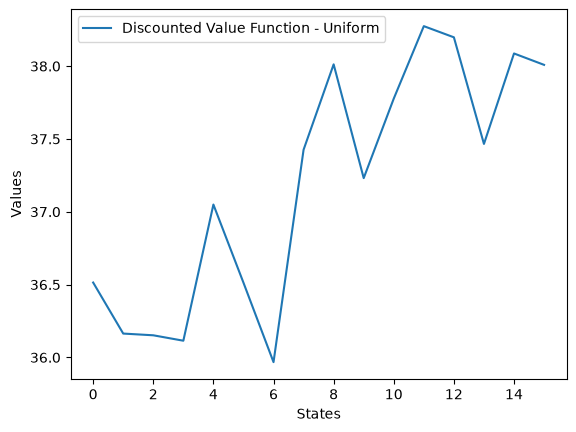

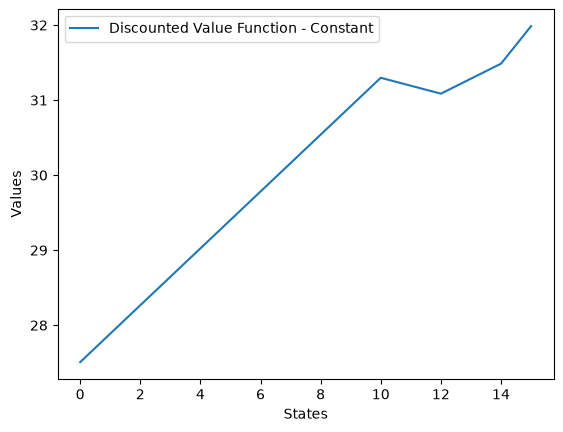

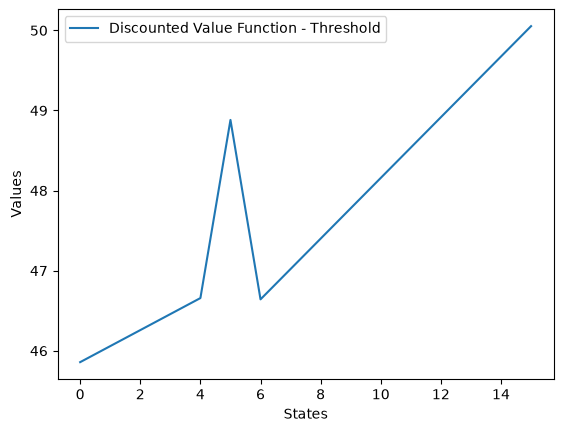

In [58]:
print(
    "The estimated Discounted Value Function in each states for the threshold policy are:"
)
print(DTValuesMC_T)

plt.figure()
plt.plot(DTValuesMC_U, label="Discounted Value Function - Uniform")
plt.legend()
plt.xlabel("States")
plt.ylabel("Values")

plt.figure()
plt.plot(DTValuesMC_C, label="Discounted Value Function - Constant")
plt.legend()
plt.xlabel("States")
plt.ylabel("Values")

plt.figure()
plt.plot(DTValuesMC_T, label="Discounted Value Function - Threshold")
plt.legend()
plt.xlabel("States")
plt.ylabel("Values")

**Bonus: Did you expect that? Try to interpret the plot ?** 


<div style="border-left: 4px solid #2a7ae2; background-color: rgba(42, 122, 226, 0.10); padding: 6px 14px; border-radius: 4px;">

We analyze the value function estimated for the uniform policy, the constant policy and the threshold policy. As the policy changes, the vlaue of a given state is not the same. Indeed, from a given state, acting according to a different policy changes the futures rewards obtained from that state. Under some policy, being in a given state may be very good, while under another policy not so.

For both the constant and uniform policies, globally, the value grows with the stock of bikes, ie states with the larger stocks have larger values. This is expected as having a large number of bikes means we can sell more of them the next week.

For the threshold policy, we observe the same behavior, as well as a spike at the state 5, ie the state in which we have 5 bikes in stock. The threshold policy orders 10 bikes if the stock is below 4. So this spike is explained by the fact that when we are in state 5, the next state will end up below 4 and 10 bikes will be ordered, most of them will be sold and we will get some reward.
</div>

**Write a Monte Carlo algorithm to estimate the cumulative reward value function $V_1^\pi(s)$ for $H = 52$** 

We collect `MC` values for the sum of rewards over $H = 52$ time step of trajectories starting at $s$, then compute the mean of these `MC` values.

In [ ]:
Policy = MakeThresholdPolicy()

MC = 100  # number of Monte-Carlo simulations
H = 52
CTValuesMC = np.zeros(M + 1)

for i in range(M + 1):
    s1 = i
    val = 0
    for j in range(MC):
        States, Rewards = ...  # TODO
        val += ...  # TODO
    CTValuesMC[i] = val / MC

In [ ]:
print(
    "The estimated Cumulative Reward Value Function in each states for the threshold policy are:"
)
print(CTValuesMC)
plt.figure()
plt.plot(CTValuesMC, label="Cumulative Reward Value Function")
plt.legend()
plt.xlabel("States")
plt.ylabel("Values")

**Bonus : How would you be able to improve the sample complexity (total number of Monte Carlo trial) to estimate $V^\pi$ or $V_1^\pi$. How to use less or equal number of sample to have a better estimation (Very hard and vague question, don't spend too much time on it)**

<div style="border-left: 4px solid #2a7ae2; background-color: rgba(42, 122, 226, 0.10); padding: 6px 14px; border-radius: 4px;">

**Your answer:**

<!-- Write your answer below this line, and keep the </div> at the end. -->



</div>

#### Iterated Bellman operator method 

**For the discounted reward function $V^\pi$ implement a function that evaluates a deterministic policy Pi by iterating the Bellman Operator for that policy.**

Unlike the previous evaluation method, this one requires the knowledge of $P$ and $r$.

This is an "approximate" method.

In [ ]:
def EvaluatePolicyIterative(Pi, eps=10**-8):
    # input: function (could also be vector as we can only use this method for deterministic policies)

    r_Pi = np.zeros((M + 1, 1))
    P_Pi = np.zeros((M + 1, M + 1))
    V_init = np.ones((M + 1, 1))
    V = V_init
    V_minus = np.zeros(M)
    for s in range(M + 1):
        # HINT: Compute the transition matrix and the reward vector associated with pi
        P_Pi[s, :] = ...  # TODO
        r_Pi[s] = ...  # TODO

    # np.linalg.vector_norm for the vector norm

    while np.linalg.vector_norm(V - V_minus, ord=np.inf) > eps:
        # TODO
        pass
    return V[:, 0]


Policy = MakeThresholdPolicy()
DTValuesIte = EvaluatePolicyIterative(Policy, eps=10**-8)

In [ ]:
print(
    "The estimated Discounted Value Function in each states for the threshold policy are:"
)
print(DTValuesIte)
plt.figure()
plt.plot(DTValuesIte, label="Discounted Value Function")
plt.legend()
plt.xlabel("States")
plt.ylabel("Values")

**Bonus: What are the guarantees of this estimation ?**

<div style="border-left: 4px solid #2a7ae2; background-color: rgba(42, 122, 226, 0.10); padding: 6px 14px; border-radius: 4px;">

**Your answer:**

<!-- Write your answer below this line, and keep the </div> at the end. -->



</div>

### Exact Method

In this section we propose to have “exact” method to compute $V_1^\pi$ and $V^\pi$.

#### Evaluation of $V^\pi$ 

**Implement a function that evaluates a deterministic policy Pi using the matrix inversion technique.**

In [ ]:
def EvaluatePolicyMat(Pi):
    # input: function (could also be vector as we can only use this method for deterministic policies)

    r_Pi = np.zeros((M + 1, 1))
    P_Pi = np.zeros((M + 1, M + 1))
    for s in range(M + 1):
        P_Pi[s, :] = ...  # TODO
        r_Pi[s] = ...  # TODO
    V = ...  # TODO
    return V[:, 0]


Policy = MakeThresholdPolicy()
DTValuesMat = EvaluatePolicyMat(Policy)
print(DTValuesMat)

**Compare the output with the previous methods for the same policy.**

<div style="border-left: 4px solid #2a7ae2; background-color: rgba(42, 122, 226, 0.10); padding: 6px 14px; border-radius: 4px;">

**Your answer:**

<!-- Write your answer below this line, and keep the </div> at the end. -->



</div>

In [ ]:
plt.figure()
plt.plot(DTValuesIte, label="Iterative Method")
plt.plot(DTValuesMat, label="Matrix Inversion Method")
plt.plot(DTValuesMC, label="Monte Carlo")
plt.legend()
plt.xlabel("States")
plt.ylabel("Values")

print(
    f"The difference between the iterative method and the matrix inversion one is {np.linalg.vector_norm(DTValuesMat - DTValuesIte)}"
)

**Bonus: Compare real clock speed of the iterative method and the matrix inversion one (and the Monte Carlo one)**

In [ ]:
# TODO

**Evaluate the 2 different policies and visualize their values for the different states in order to decide which one is better.** 

In [ ]:
# gamma = 0.97
m1 = 4
m2 = 10
TPolicy = MakeThresholdPolicy(m1=m1, m2=m2)
# m0 = 3
m0 = 3
CPolicy = MakeConstantPolicy(c=m0)

DTValuesMat = ...  # TODO
DCValuesMat = ...  # TODO

plt.figure()
plt.plot(DTValuesMat, label=f"Threshold Policy $m_1= {m1}$, $m_2= {m2}$")
plt.plot(DCValuesMat, label=f"Constant Policy, $m_0 = {m0}$")
plt.legend()
plt.xlabel("States")
plt.ylabel("Values")

#### Evaluation of $V^\pi_1$

**For a fixed stationary deterministic policy evaluate it using the bellman equation for horizon $H=52$**

In [ ]:
def EvaluatePolicyFiniteHorizon(Pis, H=52):
    """
    Exact evaluation of V_1^pi for a deterministic, possibly non-stationary,
    policy pi = (pi_1, ..., pi_H), by backward induction on the Bellman equations.

    Pis : list of H policies (functions s -> a); Pis[h - 1] is the policy pi_h used at week h.
          A single function is also accepted: it is then used at every week (stationary policy).
    H   : horizon (number of weeks).

    Returns
        V[1]  : the vector V_1^pi(s) for s = 0, ..., M
        V     : the full table, V[h, s] = V_h^pi(s) for h = 1, ..., H + 1 (row 0 is unused)
    """

    # A stationary policy is the special case pi_1 = pi_2 = ... = pi_H
    if callable(Pis):
        Pis = [Pis] * H
    assert len(Pis) == H, "we need exactly one policy per time step"

    # V[h, s] = V_h^pi(s). We keep the mathematical indexing h = 1, ..., H + 1.
    V = np.zeros((H + 2, M + 1))

    # Remember that V_{H+1}^pi = 0 (no reward after the last week).
    # It is already satisfied since V was initialised with zeros.

    # TODO
    pass
    return V[1], V

In [ ]:
H = 52
Policy = MakeThresholdPolicy()
CTValuesDP, CTValuesDP_all = EvaluatePolicyFiniteHorizon(Policy, H)

print(
    "The exact Cumulative Reward Value Function V_1 in each state for the threshold policy is:"
)
print(CTValuesDP)

# Comparison with the Monte Carlo estimate computed earlier (same policy, same horizon)
plt.figure()
plt.plot(CTValuesDP, label="Backward induction (exact)")
plt.plot(CTValuesMC, label="Monte Carlo")
plt.legend()
plt.xlabel("States")
plt.ylabel("Values")
plt.title(f"$V_1^\\pi$ of the threshold policy, $H = {H}$")

print(
    f"Max difference between Monte Carlo and backward induction: {np.max(np.abs(CTValuesMC - CTValuesDP)):.3f}"
)

# V_h decreases with h: fewer weeks are left to earn money
plt.figure()
for hh in [1, 13, 26, 39, 52]:
    plt.plot(CTValuesDP_all[hh], label=f"$V_{{{hh}}}^\\pi$")
plt.legend()
plt.xlabel("States")
plt.ylabel("Values")
plt.title("Value from week $h$ until the end of the year")

**Evaluate the 2 different policies for $V_1^\pi$ and visualize their values for the different states in order to decide which one is better.**

In [ ]:
H = 52
m1 = 4
m2 = 10
TPolicy = MakeThresholdPolicy(m1=m1, m2=m2)
m0 = 3
CPolicy = MakeConstantPolicy(c=m0)

CTValuesT, _ = ...  # TODO
CTValuesC, _ = ...  # TODO


plt.figure()
plt.plot(CTValuesT, label=f"Threshold Policy $m_1= {m1}$, $m_2= {m2}$")
plt.plot(CTValuesC, label=f"Constant Policy, $m_0 = {m0}$")

plt.legend()
plt.xlabel("States")
plt.ylabel("Values")
plt.title(f"$V_1^\\pi$, $H = {H}$")

## (BONUS+) Evaluation of non-deterministic policies

**Bonus: How would evaluate non-deterministic policies ? Adapt the previous section to non-deterministic policies, evaluate $V_1^\pi$ and $V^\pi$ for the uniform policy and add it to the comparison.**


A non-deterministic (stochastic) policy gives, in each state $s$, a probability distribution $\pi(\cdot \mid s)$ over the actions. We store it as a matrix `pi[s, a]` $= \pi(a \mid s)$.

<div style="border-left: 4px solid #2a7ae2; background-color: rgba(42, 122, 226, 0.10); padding: 6px 14px; border-radius: 4px;">

**Your answer:**

<!-- Write your answer below this line, and keep the </div> at the end. -->



</div>

In [ ]:
# A stochastic policy is stored as a matrix pi[s, a] = pi(a | s); each row sums to 1.


def DeterministicToMatrix(Pi):
    """Matrix of a deterministic policy Pi (function s -> a): pi(a | s) = 1 if a = Pi(s), else 0."""
    pi = np.zeros((M + 1, M + 1))
    for s in range(M + 1):
        pi[s, Pi(s)] = 1.0
    return pi


def UniformPolicyMatrix():
    """Matrix of the uniform policy (same distribution as PiUniform): a ~ Uniform{0, ..., M - s}."""
    pi = np.zeros((M + 1, M + 1))
    # TODO
    pass


def MarkovChainOfPolicy(pi):
    """
    Average the MDP over the actions chosen by pi:
        r^pi(s)     = sum_a pi(a | s) r(s, a)
        P^pi(s, s') = sum_a pi(a | s) P(s' | s, a)
    Under pi, the stock evolves as a Markov chain with transition matrix P^pi and mean reward r^pi.
    """

    r_pi = np.zeros(M + 1)
    P_pi = np.zeros((M + 1, M + 1))
    # TODO
    pass
    return P_pi, r_pi


UPi = UniformPolicyMatrix()
print("rows sum to 1:", np.allclose(UPi.sum(axis=1), 1))

### Discounted value function $V^\pi$ of a stochastic policy

In [ ]:
def EvaluateStochPolicyIterative(pi, eps=10**-8):
    """Iterate the Bellman operator V <- r^pi + gamma P^pi V until two iterates are eps-close."""

    P_pi, r_pi = MarkovChainOfPolicy(pi)
    V_minus = np.zeros(M + 1)
    # TODO
    pass


def EvaluateStochPolicyMat(pi):
    """Exact solution of V = r^pi + gamma P^pi V, i.e. V = (I - gamma P^pi)^{-1} r^pi."""
    P_pi, r_pi = MarkovChainOfPolicy(pi)
    # TODO
    pass


# Sanity check: on a deterministic policy we recover the previous result
print(  ### BEGIN SOLUTION
    "Threshold policy, |new - old| =",
    np.max(
        np.abs(
            EvaluateStochPolicyMat(DeterministicToMatrix(MakeThresholdPolicy()))
            - EvaluatePolicyMat(MakeThresholdPolicy())
        )
    ),
)

# Uniform policy: iterative vs matrix inversion
DUValuesIte = EvaluateStochPolicyIterative(UPi)
DUValuesMat = EvaluateStochPolicyMat(UPi)

plt.figure()
plt.plot(DUValuesIte, label="Iterative Method")
plt.plot(DUValuesMat, "--", label="Matrix Inversion Method")
plt.legend()
plt.xlabel("States")
plt.ylabel("Values")
plt.title("$V^\\pi$ of the uniform policy")

print(f"|iterative - matrix| = {np.linalg.vector_norm(DUValuesMat - DUValuesIte)}")

In [ ]:
# Comparison of the 3 policies for the discounted value function
m1 = 4
m2 = 10
TPolicy = MakeThresholdPolicy(m1=m1, m2=m2)
m0 = 3
CPolicy = MakeConstantPolicy(c=m0)

DTValuesMat = ...  # TODO
DCValuesMat = ...  # TODO
DUValuesMat = ...  # TODO

plt.figure()
plt.plot(DTValuesMat, label=f"Threshold Policy $m_1= {m1}$, $m_2= {m2}$")
plt.plot(DCValuesMat, label=f"Constant Policy, $m_0 = {m0}$")
plt.plot(DUValuesMat, label="Uniform Policy")
plt.legend()
plt.xlabel("States")
plt.ylabel("Values")
plt.title("Discounted value $V^\\pi$")
plt.savefig("Discounted_Value_function_policies.pdf", format="pdf")

### Finite horizon value function $V_1^\pi$ of a stochastic policy

Same backward induction as before, with $\pi_h(s)$ replaced by an average over $a \sim \pi_h(\cdot \mid s)$:
$$V_{H+1}^\pi = 0, \qquad V_h^\pi(s) = \sum_a \pi_h(a \mid s)\Big[r(s,a) + \sum_{s'} P(s' \mid s, a)\, V_{h+1}^\pi(s')\Big] = r^{\pi_h}(s) + \big(P^{\pi_h} V_{h+1}^\pi\big)(s).$$

In [ ]:
def EvaluateStochPolicyFiniteHorizon(pis, H=52):
    """
    Exact evaluation of V_1^pi for a stochastic, possibly non-stationary, policy
    pi = (pi_1, ..., pi_H) by backward induction.

    pis : list of H policy matrices, pis[h - 1][s, a] = pi_h(a | s).
          A single matrix is also accepted: it is then used at every week (stationary policy).

    Returns V[1] (the vector V_1^pi) and the full table V[h, s] = V_h^pi(s), h = 1, ..., H + 1.
    """

    if isinstance(pis, np.ndarray):  # stationary policy
        pis = [pis] * H
    assert len(pis) == H, "we need exactly one policy per time step"

    V = np.zeros((H + 2, M + 1))

    for h in range(H, 0, -1):  # backward in time
        P_pi, r_pi = MarkovChainOfPolicy(pis[h - 1])  # average over a ~ pi_h(. | s)
        # TODO
        pass
    return V[1], V


H = 52

# Sanity check: on a deterministic policy we recover the previous result
print(
    "Threshold policy, |new - old| =",
    np.max(
        np.abs(
            EvaluateStochPolicyFiniteHorizon(DeterministicToMatrix(TPolicy), H)[0]
            - EvaluatePolicyFiniteHorizon(TPolicy, H)[0]
        )
    ),
)

In [ ]:
# Comparison of the 3 policies for the finite horizon value function
CTValuesDP, _ = ...  # TODO
CCValuesDP, _ = ...  # TODO
CUValuesDP, _ = ...  # TODO

plt.figure()
plt.plot(CTValuesDP, label=f"Threshold Policy $m_1= {m1}$, $m_2= {m2}$")
plt.plot(CCValuesDP, label=f"Constant Policy, $m_0 = {m0}$")
plt.plot(CUValuesDP, label="Uniform Policy")
plt.legend()
plt.xlabel("States")
plt.ylabel("Values")
plt.title(f"Finite horizon value $V_1^\\pi$, $H = {H}$")

## Computing the Optimal Policy: Value and Policy Iteration and Optimal Bellman Operator

### Value and Policy Iteration $V^\star$

The function given below performs policy improvement, and may be useful to implement both value iteration and policy iteration. Note that the (deterministic) policy it outputs is encoded as a vector, not a function. 

In [ ]:
# policy improvement
def Improve(V):
    """computes the Q table associated to V and
    return Pi=greedy(V)=greedy(Q) as well as max_{a} Q[s,a]"""
    Pi = np.zeros(M + 1)  # improved policy
    newV = np.zeros(M + 1)
    # compute the Q table
    Q = np.zeros((M + 1, M + 1))
    for s in range(M + 1):
        for a in range(M + 1):
            Q[s, a] = r[s, a] + gamma * np.sum(
                [P[s, a, ns] * V[ns] for ns in range(M + 1)]
            )
        # improvement (greedy policy wrt to Q)
        pi = np.argmax(Q[s, :])
        Pi[s] = pi
        newV[s] = Q[s, pi]
        Pi = Pi.astype(int)
    return Pi, newV


V = np.random.randint(M + 1, size=M + 1)
newPi, newV = Improve(V)
print("improved policy from random:", newPi)

**Implement Value Iteration and Policy Iteration.**

First, check that the two algorithms output the same optimal policy. Then, you may compare the number of iteration needed by both algorithms as well as the executation time. 

In [ ]:
def ValueIteration(epsilon=1e-3):  # epsilon = guaranteed precision

    # initialization
    V = np.zeros(M + 1)
    Pi = np.zeros(M + 1)
    # new value function
    newV = 10 * np.random.rand(M + 1)
    nIt = 0
    # TODO
    pass
    return Pi, newV, nIt

In [ ]:
def PolicyIteration():

    # initalization
    Pi = np.zeros(M + 1)
    V = np.zeros(M + 1)
    # new policy
    newPi = np.random.randint(M + 1, size=M + 1)
    newPi[0] = 1
    nIt = 0
    # TODO
    pass
    return Pi, V, nIt

In [ ]:
start = time.time()
Pi_gamma_star_VI, V_gamma_star_VI, nIt = ValueIteration()
elapsed = time.time() - start

start = time.time()
Pi_gamma_star_PI, V_gamma_star_PI, nIt2 = PolicyIteration()
elapsed = time.time() - start

print(
    "Value iteration yields policy",
    Pi_gamma_star_VI,
    "and value ",
    V_gamma_star_VI,
    " in ",
    nIt,
    " iterations and t=",
    elapsed,
    " seconds\n",
)
print(
    "Optimal policy is",
    Pi_gamma_star_PI,
    "with value ",
    V_gamma_star_PI,
    " in ",
    nIt2,
    " iterations and t=",
    elapsed,
    " seconds",
)

print(
    f"The max difference between the two value function is {np.linalg.vector_norm(V_gamma_star_PI - V_gamma_star_VI)}"
)
print(
    f"The max difference between the two value function is {np.linalg.vector_norm(Pi_gamma_star_PI - Pi_gamma_star_VI)}"
)

Here is a visualization of the optimal policy. 

**What does the optimal policy look like ?**


<div style="border-left: 4px solid #2a7ae2; background-color: rgba(42, 122, 226, 0.10); padding: 6px 14px; border-radius: 4px;">

**Your answer:**

<!-- Write your answer below this line, and keep the </div> at the end. -->



</div>

In [ ]:
plt.step(range(M + 1), Pi_gamma_star_PI, where="mid")
plt.xlabel("stock")
plt.ylabel("order under the optimal policy")
plt.title("Optimal Policy")
# plt.savefig("Discounted_Optimal_Policy.pdf")

plt.figure()
plt.plot(V_gamma_star_PI)
plt.xlabel("stock")
plt.ylabel("value of the optimal policy")
plt.title("Optimal Value")

Vstar = np.copy(V_gamma_star_PI)

### Bellman equations for the optimal values $V_1^\star$

**Implement the bellman optimal equation**

In [ ]:
def OptimalFiniteHorizon(H=52):
    """
    Backward induction on the optimal Bellman equations for horizon H.

    Returns
        Pis : array of shape (H + 1, M + 1), Pis[h, s] = pi_h^*(s) for h = 1, ..., H (row 0 is unused)
        V   : array of shape (H + 2, M + 1), V[h, s] = V_h^*(s) for h = 1, ..., H + 1 (row 0 is unused)
    """

    V = np.zeros((H + 2, M + 1))  # V[H + 1] = 0: terminal condition
    Pis = np.zeros((H + 1, M + 1), dtype=int)

    # TODO
    pass
    return Pis, V


H = 52
PiStarH, VStarH = OptimalFiniteHorizon(H)
print(r"V_1^\star = ", VStarH[1])

In [ ]:
# V_1^* must dominate the value of every other policy
plt.figure()
plt.plot(VStarH[1], "k", linewidth=2, label="Optimal $V_1^\\star$")
plt.plot(CTValuesDP, label=f"Threshold Policy $m_1= {m1}$, $m_2= {m2}$")
plt.plot(CCValuesDP, label=f"Constant Policy, $m_0 = {m0}$")
plt.plot(CUValuesDP, label="Uniform Policy")
plt.legend()
plt.xlabel("States")
plt.ylabel("Values")
plt.title(f"Finite horizon values $V_1^\\pi$, $H = {H}$")
plt.savefig("Value_function_policies_optimal.pdf", format="pdf")

**Compare the different policies at different time, what can you say about them ?**

<div style="border-left: 4px solid #2a7ae2; background-color: rgba(42, 122, 226, 0.10); padding: 6px 14px; border-radius: 4px;">

**Your answer:**

<!-- Write your answer below this line, and keep the </div> at the end. -->



</div>


In [ ]:
# A few weeks: the policy is stationary for most of the year and changes in the last weeks
plt.figure()
for hh in [1, H - 2, H - 1, H]:
    plt.step(range(M + 1), PiStarH[hh], where="mid", label=f"$\\pi_{{{hh}}}^\\star$")
# Stationary threshold policy, for comparison
plt.step(
    range(M + 1),
    [TPolicy(s) for s in range(M + 1)],
    "k--",
    where="mid",
    label=f"Threshold Policy $m_1= {m1}$, $m_2= {m2}$",
)
plt.legend()
plt.xlabel("stock $s$")
plt.ylabel("order")
plt.title("Optimal policy at different weeks")


### $\pi^\star_\gamma$ vs $\pi^\star_1$

Here we call $\pi^\star_\gamma$ the optimal policy for the discounted reward and $\pi^\star_1$ the optimal policy at $h=1$ for the finite horizon value function. 

**Compare them, what can you say about $V_1^{\pi^\star_\gamma}$ when $\pi^\star_\gamma$ is used at every time step $h$**


<div style="border-left: 4px solid #2a7ae2; background-color: rgba(42, 122, 226, 0.10); padding: 6px 14px; border-radius: 4px;">

**Your answer:**

<!-- Write your answer below this line, and keep the </div> at the end. -->



</div>

In [ ]:
# TODO

**(Bonus) are they always equal ? Give an example.**

<div style="border-left: 4px solid #2a7ae2; background-color: rgba(42, 122, 226, 0.10); padding: 6px 14px; border-radius: 4px;">

**Your answer:**

<!-- Write your answer below this line, and keep the </div> at the end. -->



</div>

## (Bonus ++) An optimal policy is threshold ? 

The threshold policy `PiThreshold(s, m1, m2)` ("if the stock is at most $m_1$, refill up to $m_2$") is called an **$(s, S)$ policy** in inventory theory, with $s = m_1$ and $S = m_2$:
$$\pi(x) = \begin{cases} S - x & \text{if } x \le s,\\ 0 & \text{otherwise.}\end{cases}$$
In the previous section, every $\pi_h^\star$ we plotted looked like such a policy, but with thresholds that depend on $h$.

1. Write a function that, given a table $Q(s, a)$, finds an $(s, S)$ policy that is greedy with respect to $Q$, or returns `None` if there is none. *Careful: several actions may reach the max (ties), so do not just test `np.argmax`.*
2. Check (numerically) that each $\pi_h^\star$, $h = 1, \dots, H$, and the discounted optimal policy $\pi^\star_\gamma$ can be chosen to be an $(s, S)$ policy. How do the thresholds evolve with $h$?
3. What is the role of the fixed cost $c_0$? Recompute the optimal policies for $c_0 = 0$ and for a large $c_0$.
4. Is it a coincidence of our parameters? Repeat the check for other demand distributions and costs.
5. Is the optimal policy of *any* MDP a threshold policy? What property of this problem makes it true here?

In [ ]:
# 1. Find an (s, S) policy that is greedy with respect to a Q table
def FindThreshold(Q, tol=1e-9):
    """
    Look for an (s, S) policy  pi(x) = S - x if x <= s, 0 otherwise,
    such that Q(x, pi(x)) = max_a Q(x, a) in every state x (up to tol, to handle ties).
    Returns (s, S), or None if there is no such policy. s = -1 means "never order".
    """
    # TODO
    pass


def PrintThresholds(Qs, H):
    """Qs[h] = Q_h table for h = 1..H. Prints the (s, S) thresholds, grouping consecutive weeks."""
    Th = {hh: FindThreshold(Qs[hh]) for hh in range(1, H + 1)}
    start = 1
    for hh in range(2, H + 2):
        if hh == H + 1 or Th[hh] != Th[start]:
            print(f"  weeks {start:2d}-{hh - 1:2d}: (s, S) = {Th[start]}")
            start = hh
    return Th


# 2. Finite horizon: Q_h^*(s, a) = r(s, a) + sum_s' P(s'|s, a) V_{h+1}^*(s')
# TODO

In [ ]:
# 3. Role of the fixed cost c0
def BuildMDP(pdem_, M_=15, h_=0.3, c_=0.5, c0_=0.3, p_=1):
    """Same P and r as in StoreManagement, but for any demand distribution pdem_."""
    P_ = np.zeros((M_ + 1, M_ + 1, M_ + 1))
    r_ = np.zeros((M_ + 1, M_ + 1))
    for a in range(M_ + 1):
        for s in range(M_ + 1):
            for d in range(M_ + 1):
                P_[s, a, nextstate(s, a, d, M_)] += pdem_[d]
                r_[s, a] += pdem_[d] * nextreward(s, a, d, M_, c_, c0_, h_, p_)
    return P_, r_


def BackwardInductionQ(P_, r_, H):
    """Optimal Bellman equations for horizon H; returns Qs[h] = Q_h^* for h = 1..H."""
    Qs = [None] * (H + 1)
    V_next = np.zeros(P_.shape[0])  # V_{H+1}^* = 0
    for hh in range(H, 0, -1):
        Qs[hh] = r_ + P_ @ V_next
        V_next = Qs[hh].max(axis=1)
    return Qs


# TODO

In [ ]:
# 4. Robustness: other demand distributions and costs
from math import exp, factorial


def Truncate(w):
    """Normalise weights w on {0, ..., M-1} and put the remaining mass on M (as for the geometric demand)."""
    pd_ = np.zeros(M + 1)
    pd_[:M] = w[:M]
    pd_[M] = 1 - pd_[:M].sum()
    return pd_


Demands = {}
for q_ in [0.05, 0.1, 0.2, 0.4]:
    Demands[f"geometric q={q_}"] = Truncate(
        np.array([q_ * (1 - q_) ** m for m in range(M + 1)])
    )
for lam in [3, 7, 11]:
    Demands[f"Poisson lambda={lam}"] = Truncate(
        np.array([exp(-lam) * lam**m / factorial(m) for m in range(M + 1)])
    )
bimodal = np.zeros(M + 1)
bimodal[[1, 12]] = 0.5
Demands["bimodal {1, 12}"] = bimodal

# TODO

<div style="border-left: 4px solid #2a7ae2; background-color: rgba(42, 122, 226, 0.10); padding: 6px 14px; border-radius: 4px;">

**Your answer:**

<!-- Write your answer below this line, and keep the </div> at the end. -->



</div>